# N113: action/sequence margins and stalled-copy checks

Status: **stopped**.

Two matched H2 runs start independently from the ORIGINAL image-model, optimizer
and RNG parent. Each sees the same ordered 91,968 reserved images, excluding all
4,032 offline images. Rates are {0, 1/8, 1/4} of ORIGINAL nominal LR. The four-head
ridge, 88 rich features, fixed-context rollout, original J, 5% feasible-action
exploration, health-floor fractions (90% RankMe, 80% variance), peak-EMA anchor,
256-feedback-arrival forgetting and 384-arrival readouts are otherwise retained.
N112's stopped H2 checkpoint is preserved and is NOT the starting parent.

| New arm | H2 uncertainty | Temporary-copy checks |
| --- | --- | --- |
| D: action/sequence margins | Calibrated physical-rate scales | None |
| E: same + copy checks | Identical initial calibration and floor rule | Triggered by constraint starvation |

Margin scales are prescribed before calibration, not optimized on results:
one-step s(a)=a/(1/4); two-step s(a,b)=(a+b)/(1/4). For a second action of skip,
use exactly the first-step uncertainty and health, including zero for skip/skip.
For positive second actions, calibrate actual two-step residuals, including the
unknown-next-image error of skip/train under the fixed-context approximation.
On the original offline VALIDATION parents only, take the maximum normalized
one-sided overprediction residual across positive actions or positive-second
paths, then the same finite-sample quantile at alpha/4 per health/horizon family.
The normalized two-step quantile is at least the one-step quantile. TRAIN-only
predictor/transforms are reused byte-for-byte; TEST is diagnostic only, never fit
or tuned. This is an adaptive development experiment on previously inspected data,
not a fresh confirmatory test or a formal online safety guarantee.

Online quantiles can only widen relative to frozen offline quantiles, using the
last 512 normalized feedback-parent scores, with at least 80 scores. A train/skip
pair adds no second-step calibration observation. Copied rates contribute a max
residual per audit parent rather than two independent calibration parents.

In E, count consecutive arrivals with no feasible positive first-action H2 plan.
Ordinary objective-selected skips do not count. First audit at 512 blocked arrivals;
repeat every 256 while blocked. Do not audit during numerical cooldown or while
committing an ordinary positive action. Reset starvation after a committed update
or when a positive-action plan becomes feasible. At each audit test exactly the
two positive rates on independent restored copies of the current complete learner
state, same current image and augmentation seed, no future images or task labels.

Measure actual [delta-J, delta-RankMe, delta-reconstruction, delta-variance]. A
passing trial must retain BOTH pre-decision frozen health floors and improve
measured original J by more than 1e-6. Adopt the lowest-J passing copy's exact model,
optimizer, modes and RNG state, without re-training; its verified H2 backup is
(measured update, skip). Replan next arrival as in receding-horizon MPC. If none
passes, leave the live learner unchanged. A failed numerical trial provides no
label. Measured checks certify these fixed-bank outcomes only, not future images
or task accuracy. Floors never relax to force learning.

All valid copied outcomes, including rejected copies, provide actual predictor
feedback. Their weights sum to ONE arrival: apply forgetting once then add the
average sufficient statistics across valid copied rates. A committed audit winner
is not learned a second time. Ordinary successful updates retain the old one-row
rule. The anchor advances only on committed plant updates, never on rejected
copies. This deliberate feedback-policy change is isolated in E.

No temporary model weights are written to disk. Audit arrays store rates, validity,
seven measured health metrics, trained-image losses, passing flags, choice and
elapsed time. Two DEFLATE checkpoint generations retain only the committed learner
and complete controller/RNG/feedback state. Audit attempts, valid trial labels,
verified re-entries and audit wall time are reported separately from plant updates
and committed learning-rate budget. Snapshot/restore time is included in audit cost.

Preflight checks cover exact full/resumed GPU continuation, committed-optimizer
accounting, audit rejection preserving plant state, accepted-copy adoption,
numerical trial failure exclusion, action masking and exact causal predictor,
bound and starvation-clock replay. Preflights use offline TRAIN images only.


| Arm | Saved images | Plant updates | Predictor feedback arrivals | Available late probe (%) | Recorded time (min) |
| --- | ---: | ---: | ---: | ---: | ---: |
| H2 · Action/sequence margins | 91,968 | 3,194 | 3,194 | 63.076 | 48.30 |
| H2 · Same margins + copy checks | 56,833 | 3,194 | 3,291 | 63.066 (partial) | 29.44 |

Common coverage across both arms: **56,833**. Available table means use each arm's saved coverage; primary comparisons use common scheduled30k--91,968 checkpoints.

## Positive-update one-step forecast RMSE

| Arm | Output | Active model | Frozen shadow, same states/actions | Persistence | Positive updates |
| --- | --- | ---: | ---: | ---: | ---: |
| H2 · Action/sequence margins | RankMe | 0.00426095 | 0.00541154 | 0.00765764 | 3,194 |
| H2 · Action/sequence margins | Reconstruction loss | 0.000410448 | 0.000780624 | 0.000718973 | 3,194 |
| H2 · Action/sequence margins | Variance | 1.99209e-05 | 3.15623e-05 | 3.81561e-05 | 3,194 |
| H2 · Same margins + copy checks | RankMe | 0.00426095 | 0.00541154 | 0.00765764 | 3,194 |
| H2 · Same margins + copy checks | Reconstruction loss | 0.000410448 | 0.000780624 | 0.000718973 | 3,194 |
| H2 · Same margins + copy checks | Variance | 1.99209e-05 | 3.15623e-05 | 3.81561e-05 | 3,194 |

RMSE is in native metric units. Different policies visit different states; the frozen-shadow comparison is paired within each plant trajectory. Per-action and two-step numbers/counts are saved in comparison.json.


## Balanced audit linear accuracy (%)

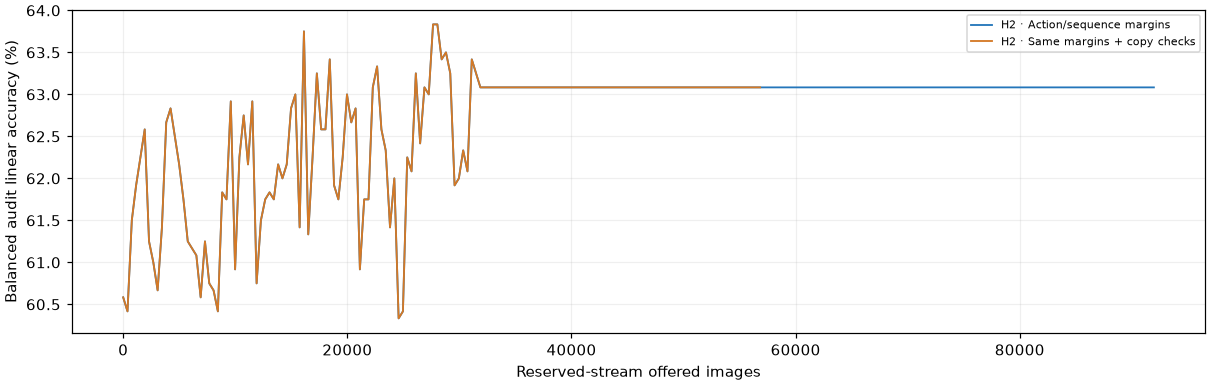



## RankMe

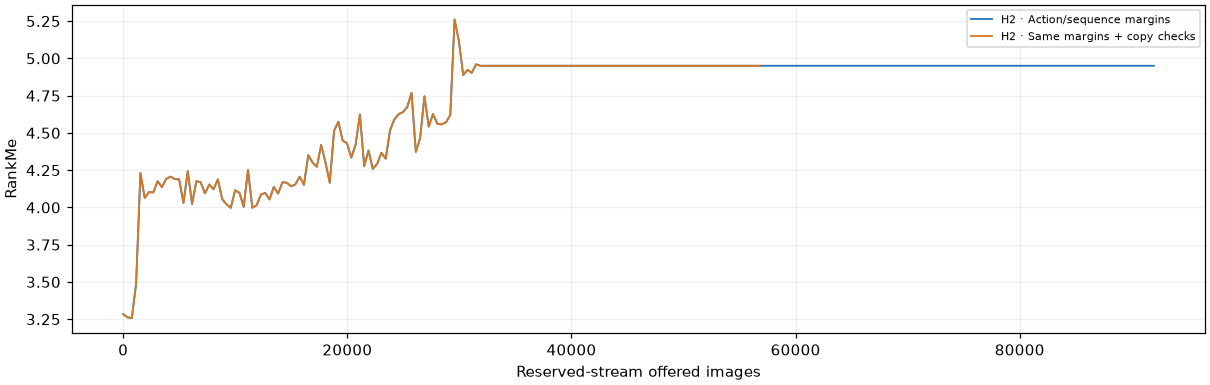



## Fixed-bank reconstruction loss

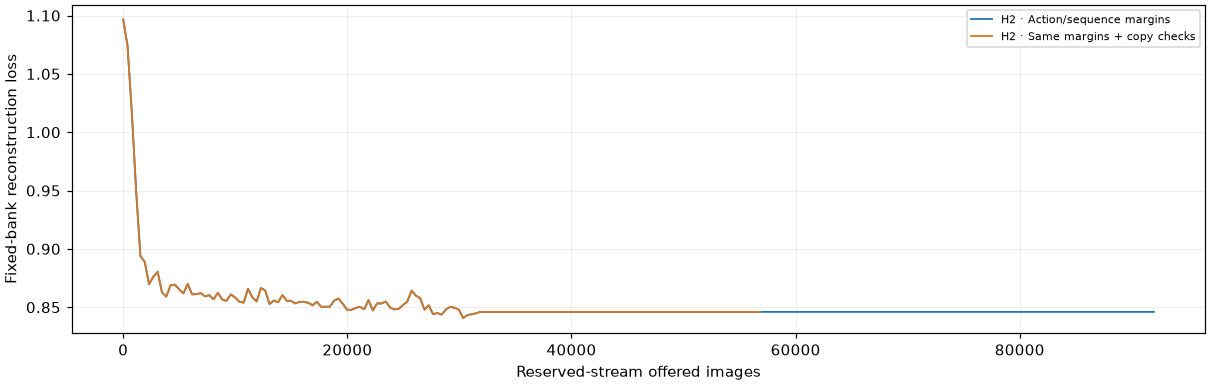



## Variance

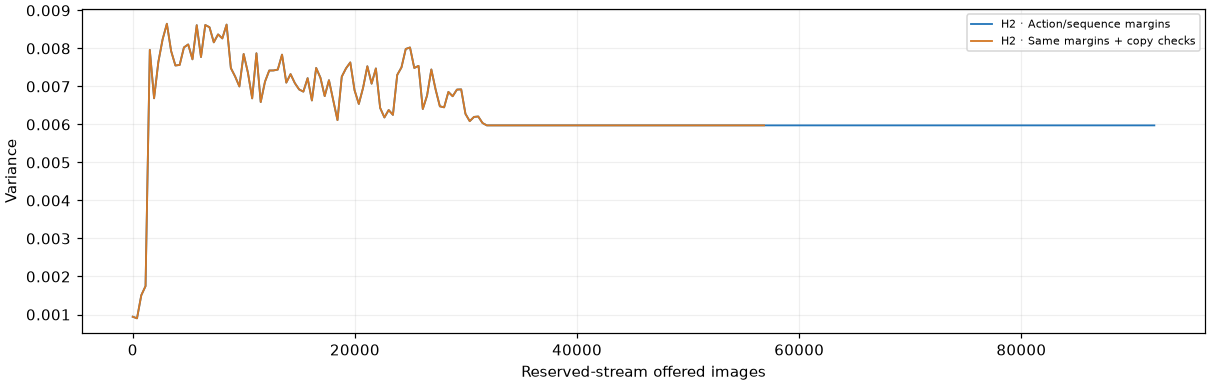



## Original fixed-bank J

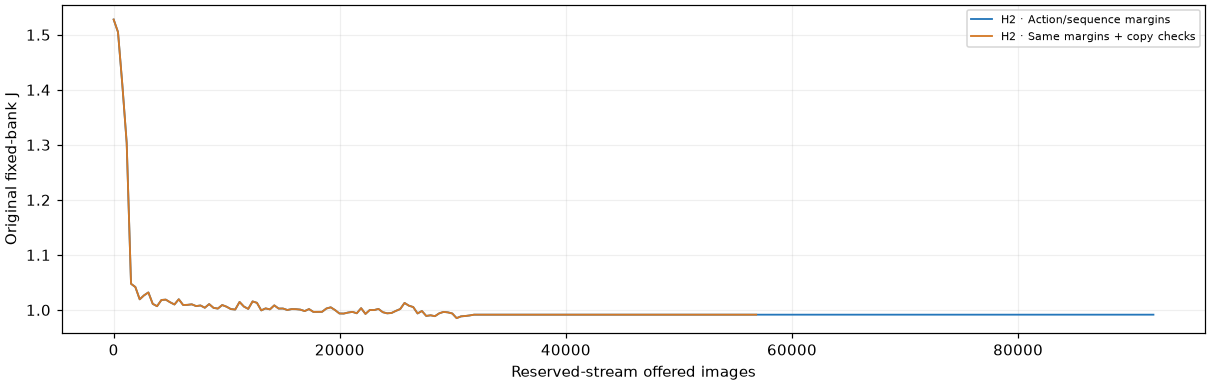



## Covariance

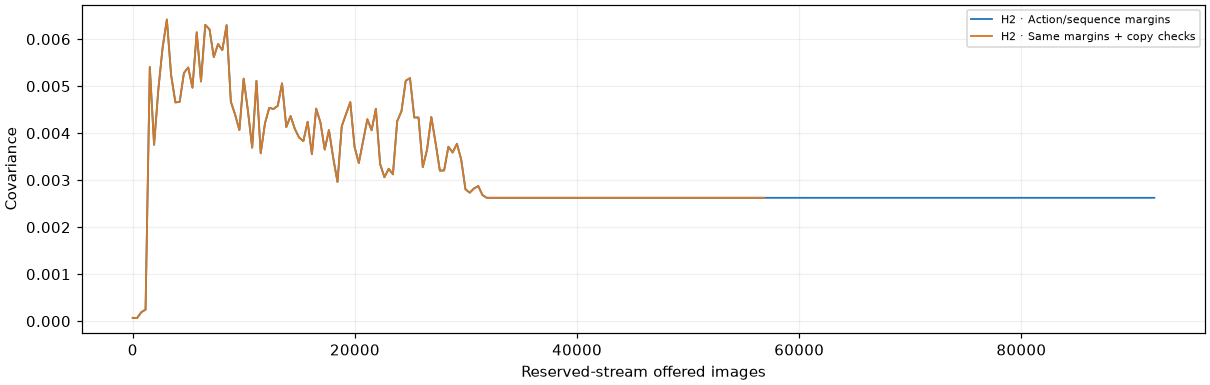



## Actual plant outputs and one-step forecasts

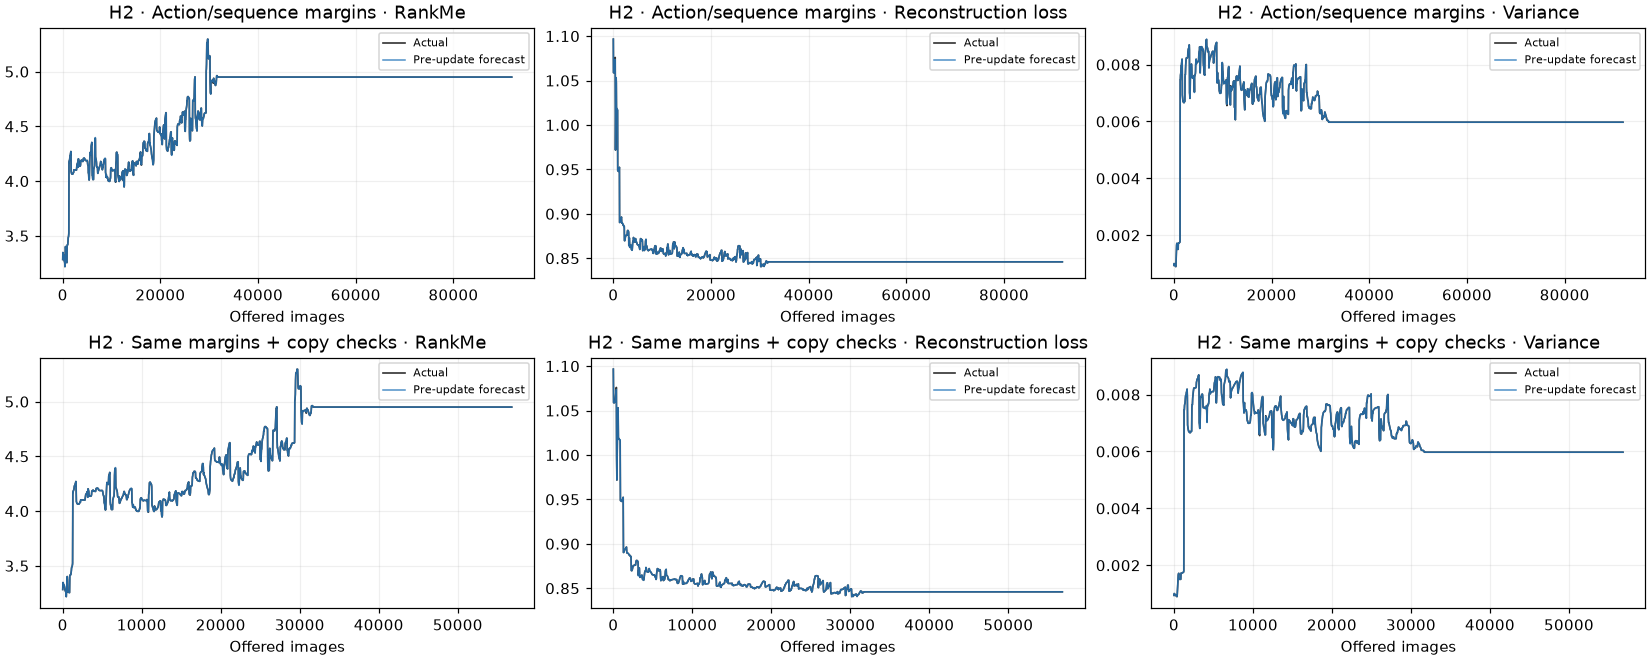

Display subsamples every32 arrivals; RMSE uses all successful positive updates and excludes identity skips.

## One-step positive-update RMSE

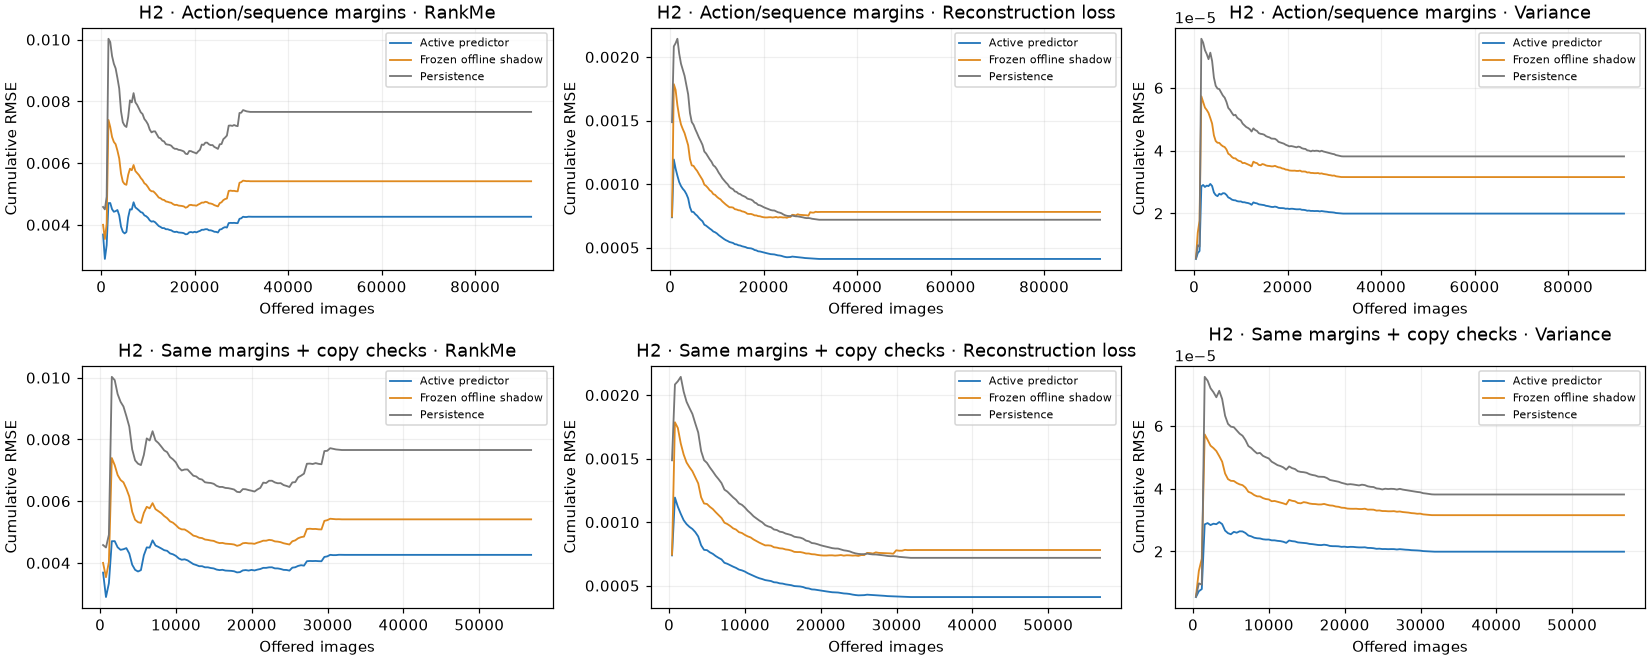



## Two-step nontrivial-window RMSE

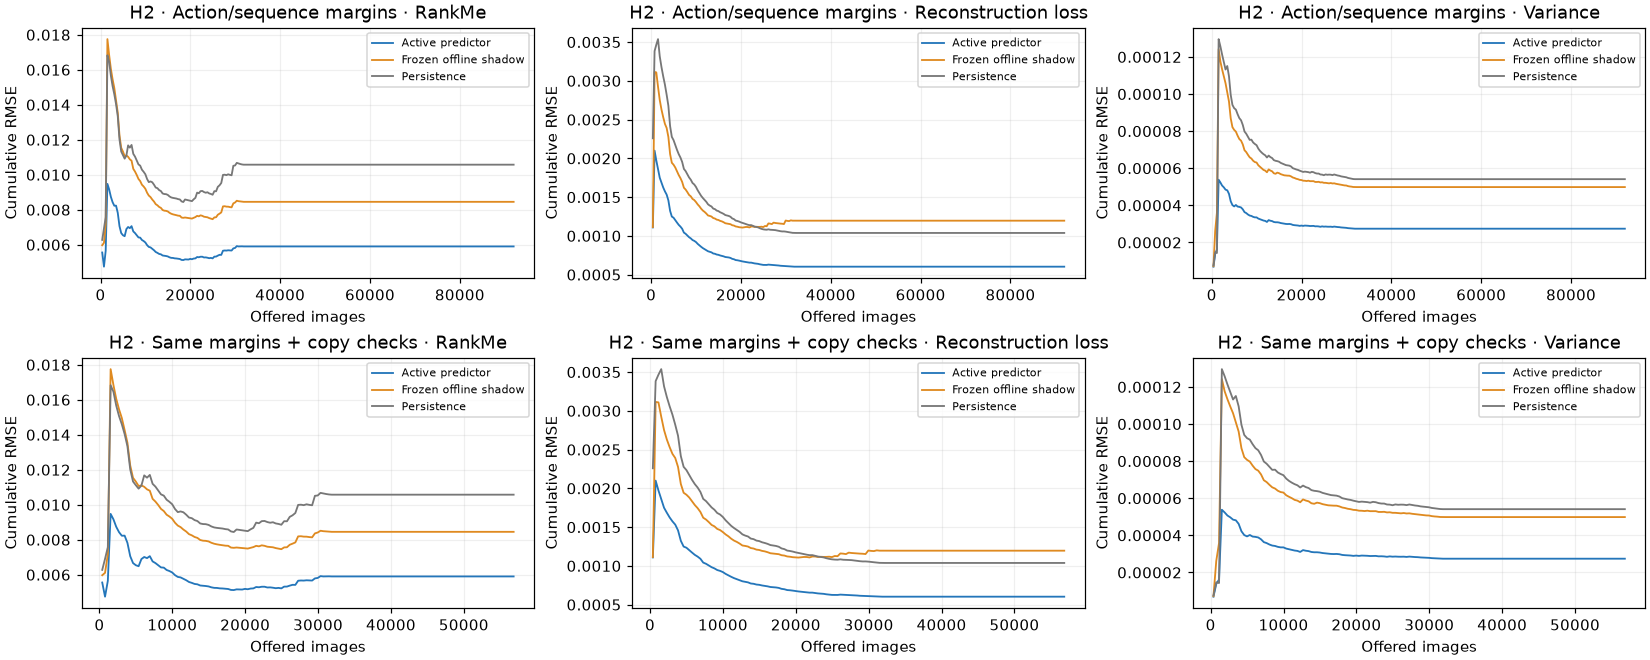



## Plant update and rate budgets

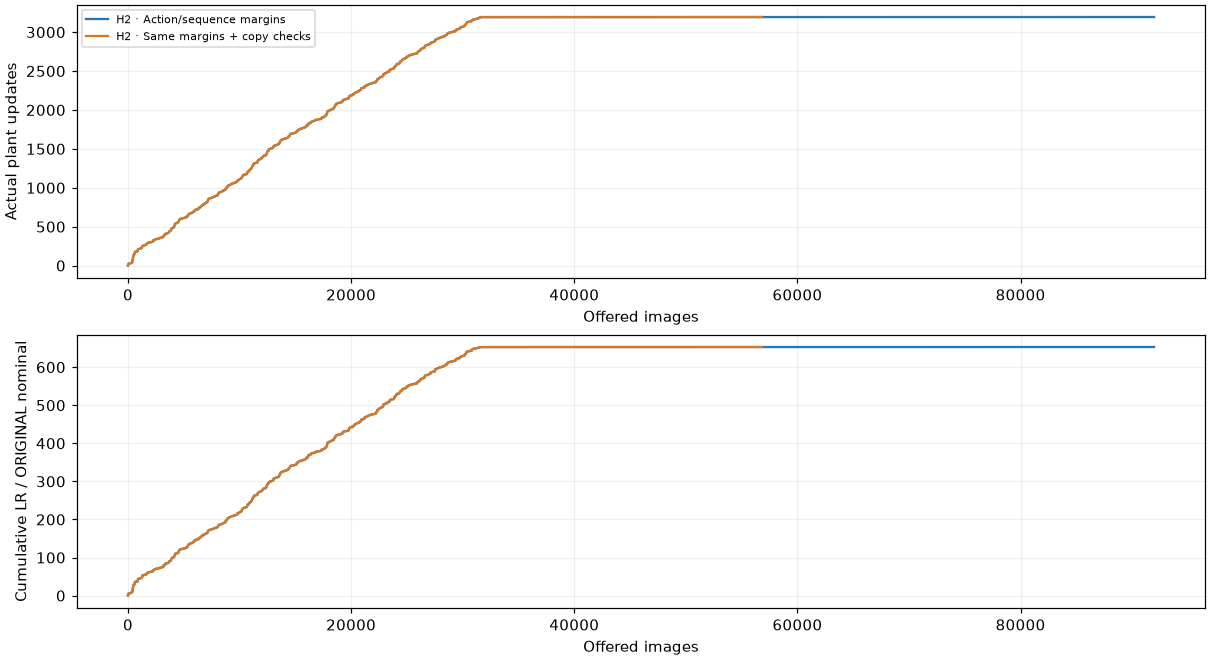



## Transition-model adaptation

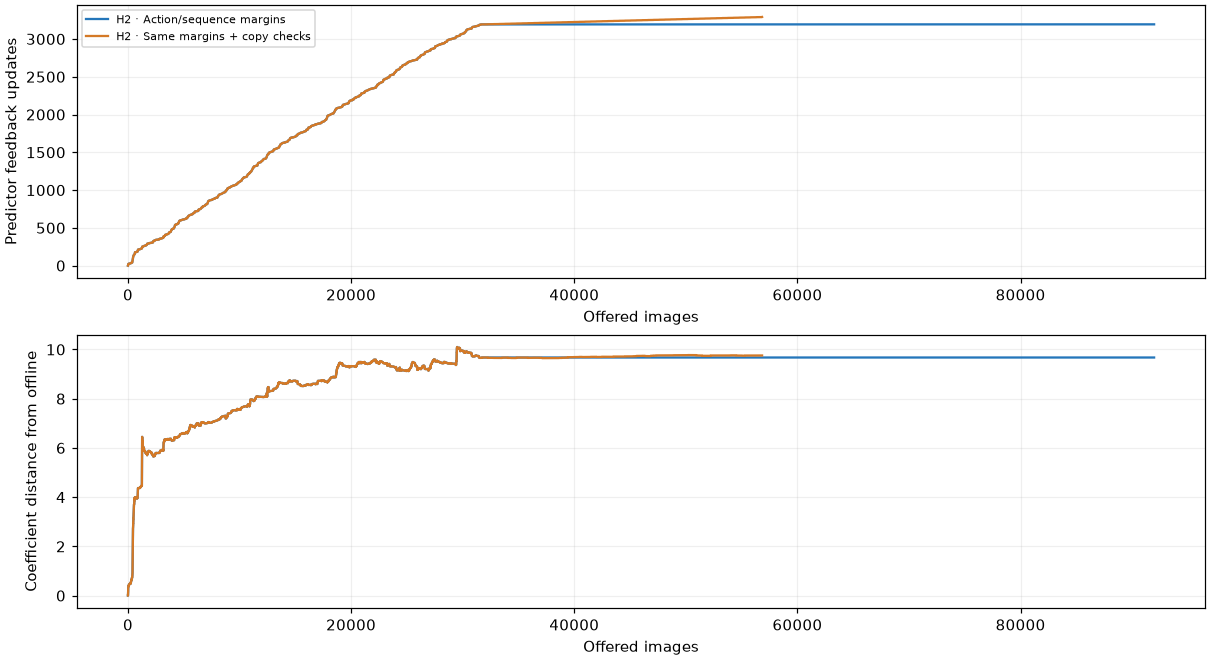



## Executed learning-rate actions

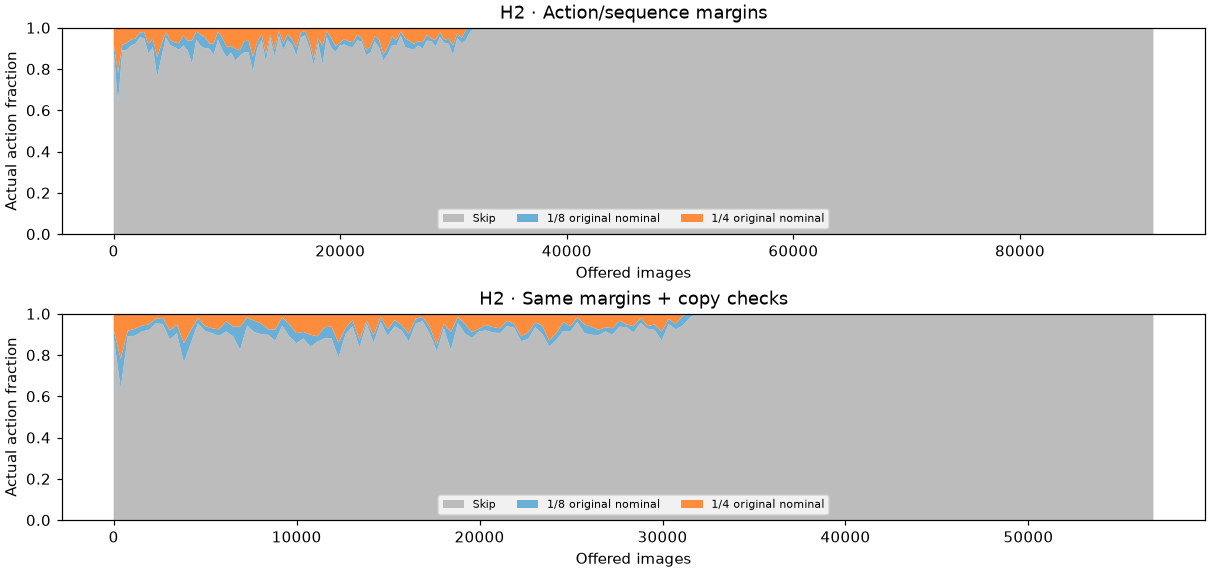



## Actual trained-image losses

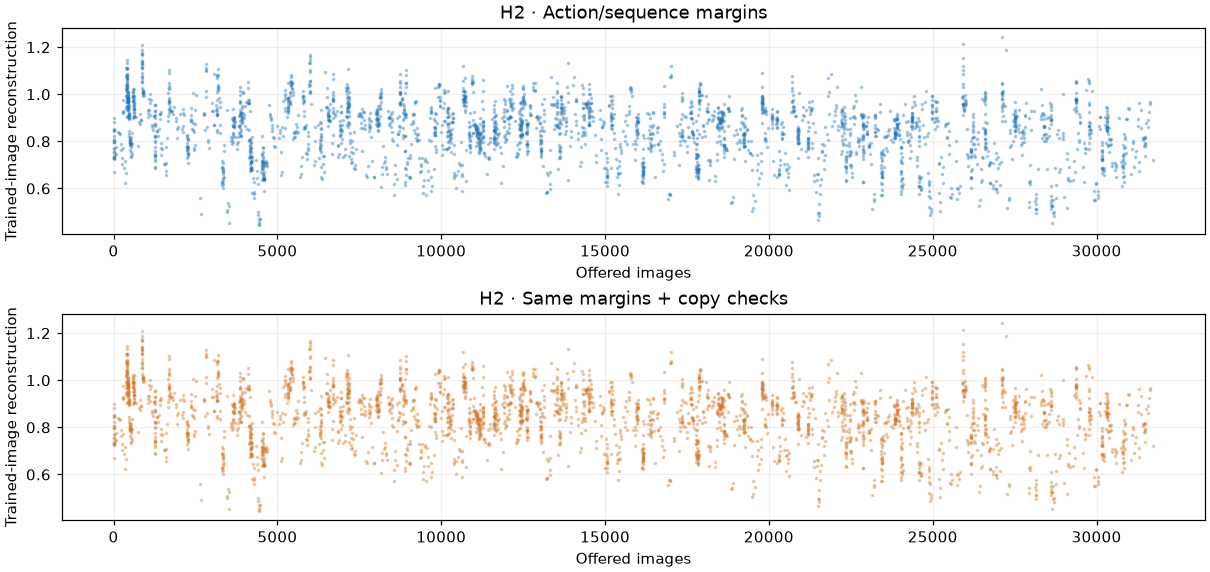



## Audit: linear task metrics

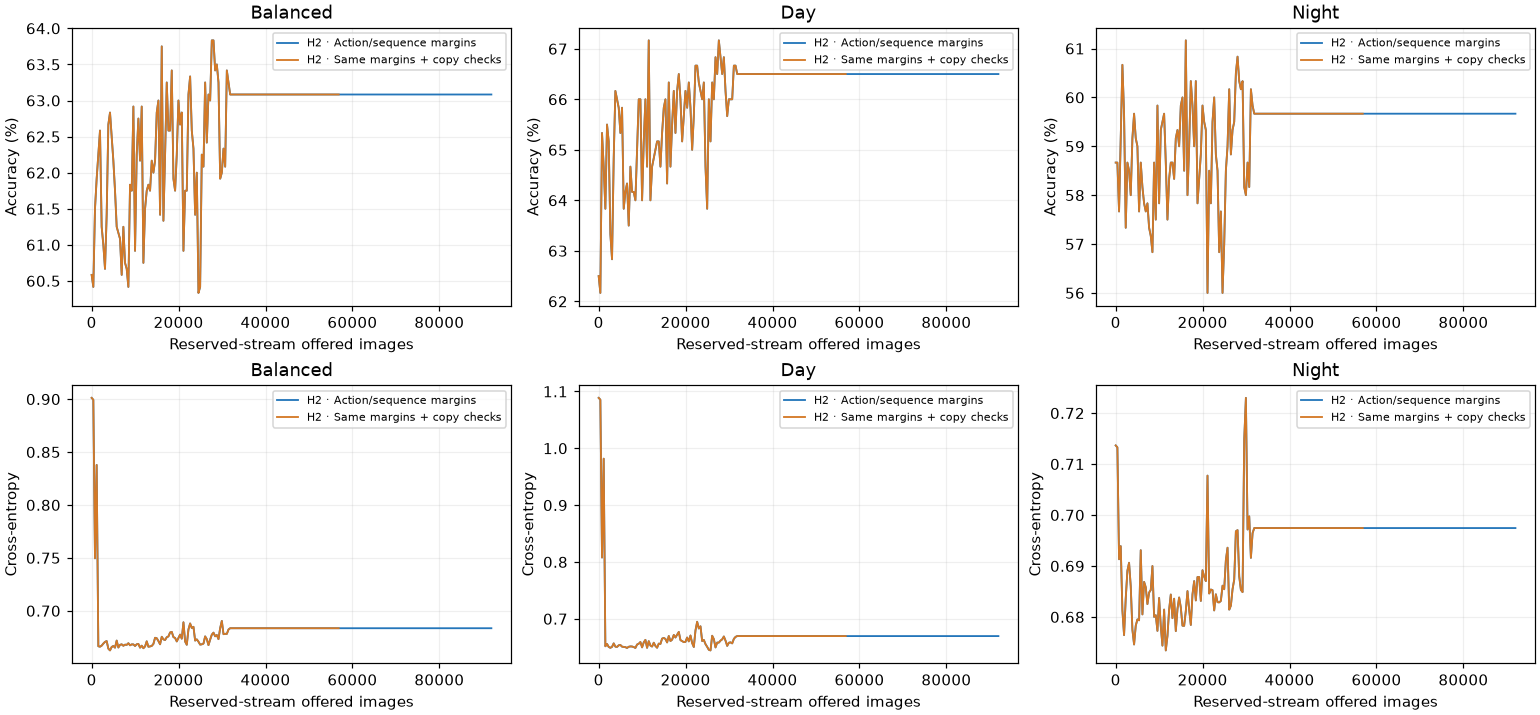



## Audit: knn task metrics

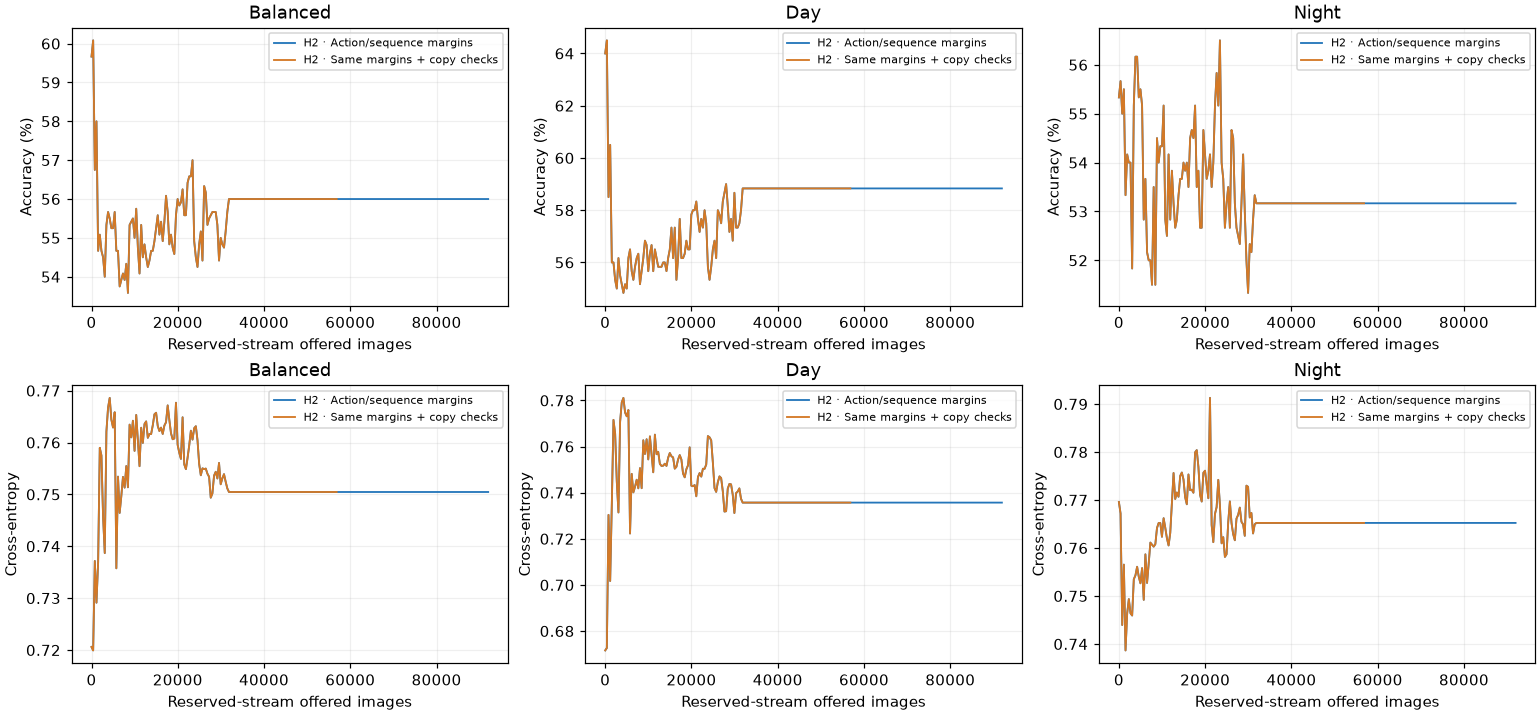



## Previous evaluation: linear task metrics

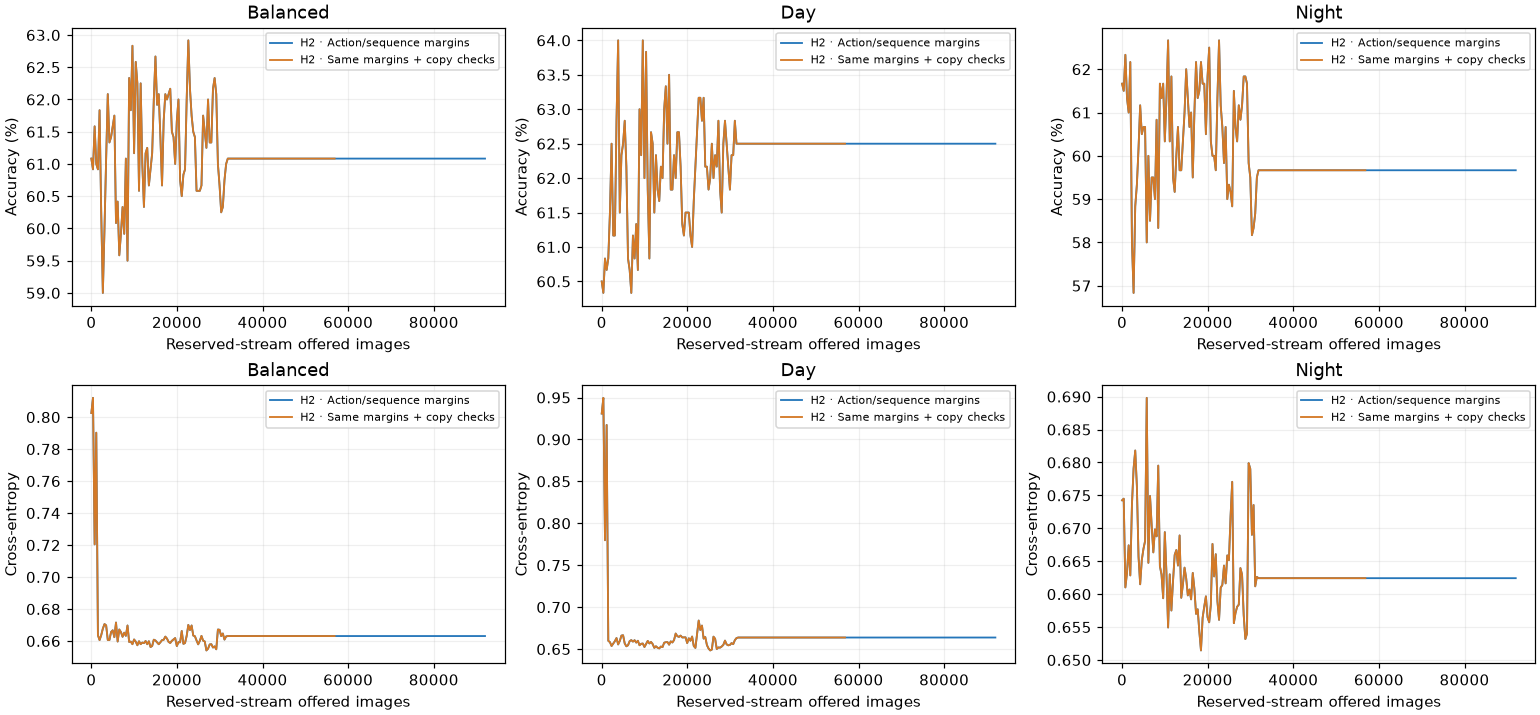



## Previous evaluation: knn task metrics

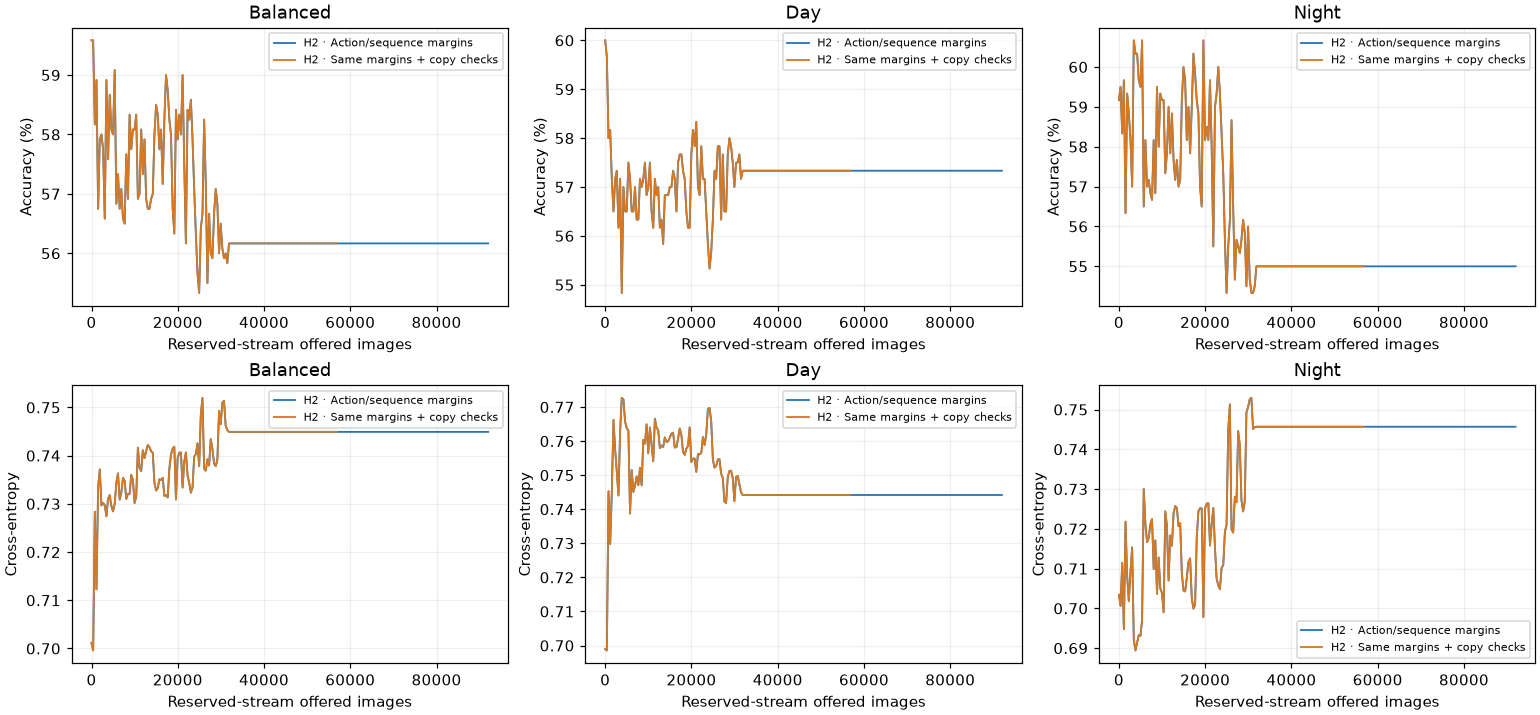



## Additional representation metrics

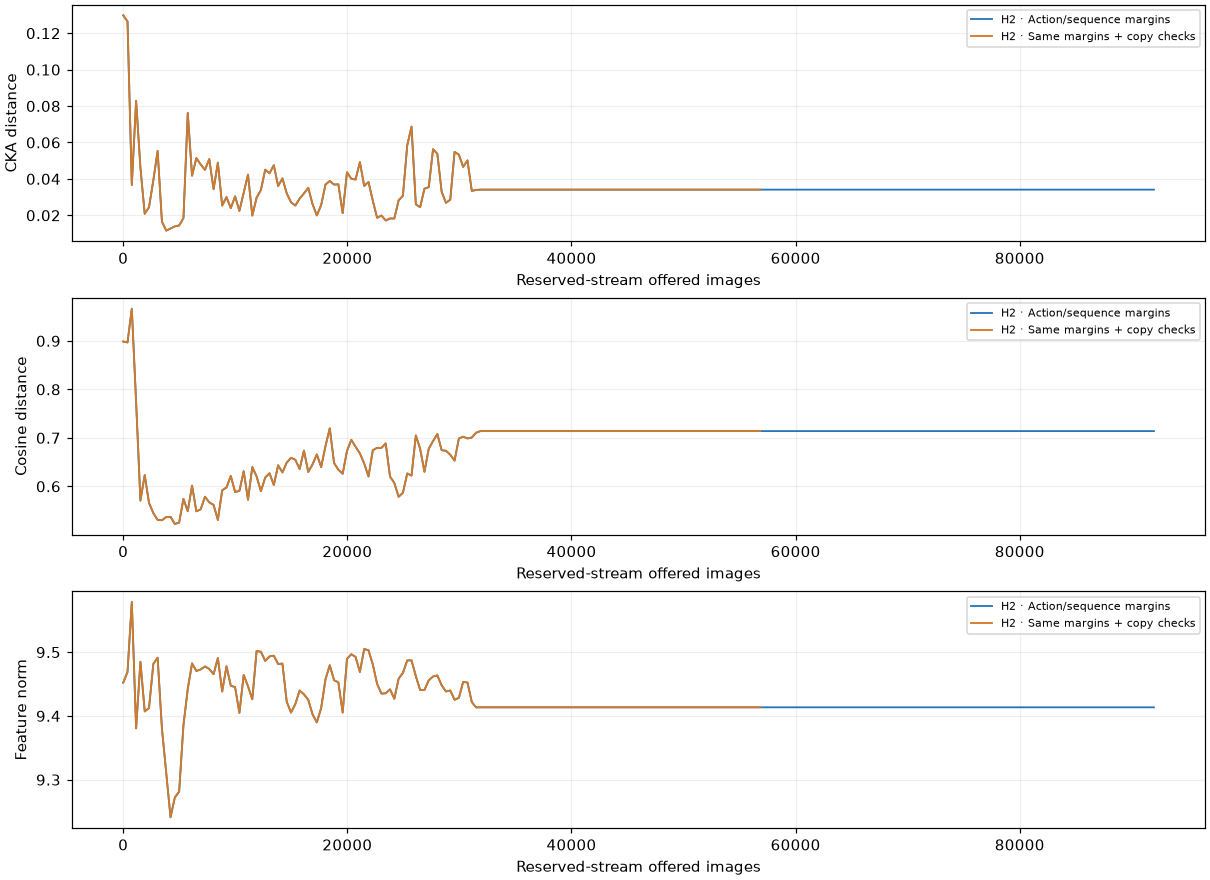



## Secondary evaluation health

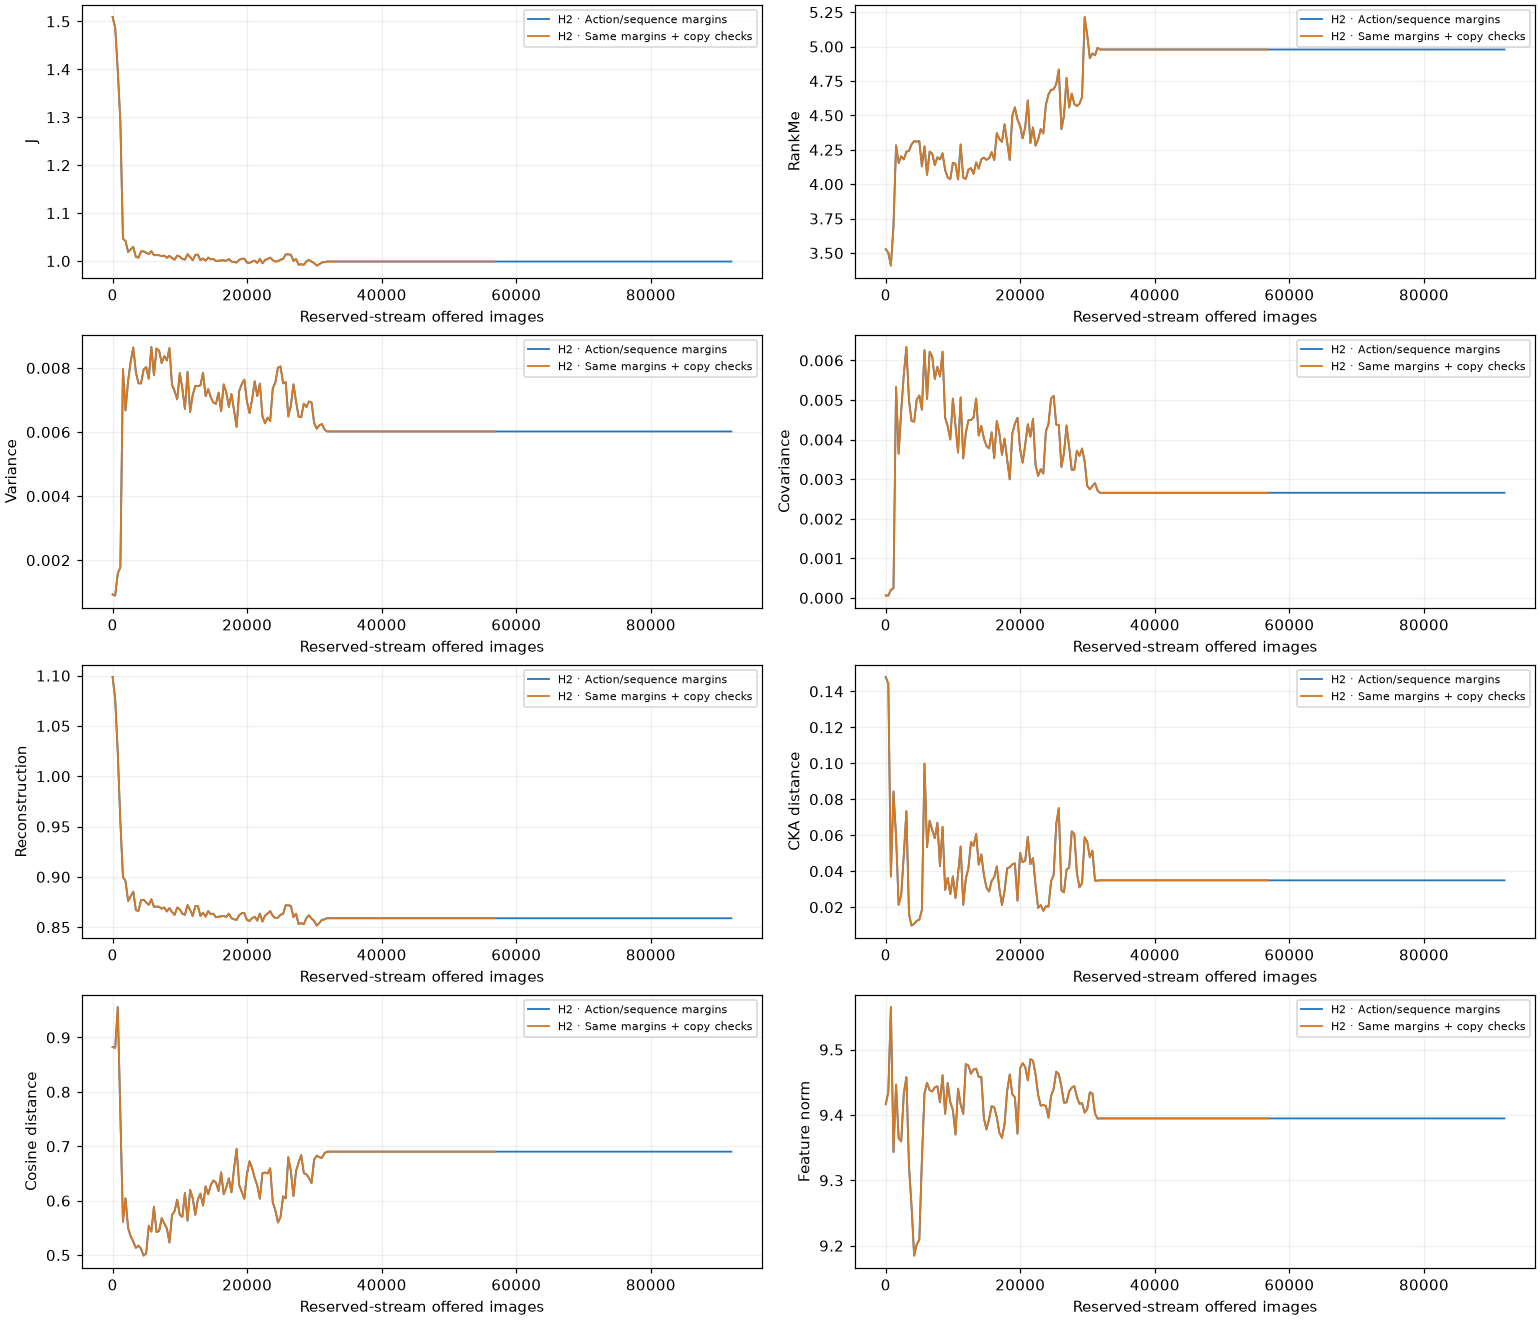



## Actual health versus pre-action causal floors

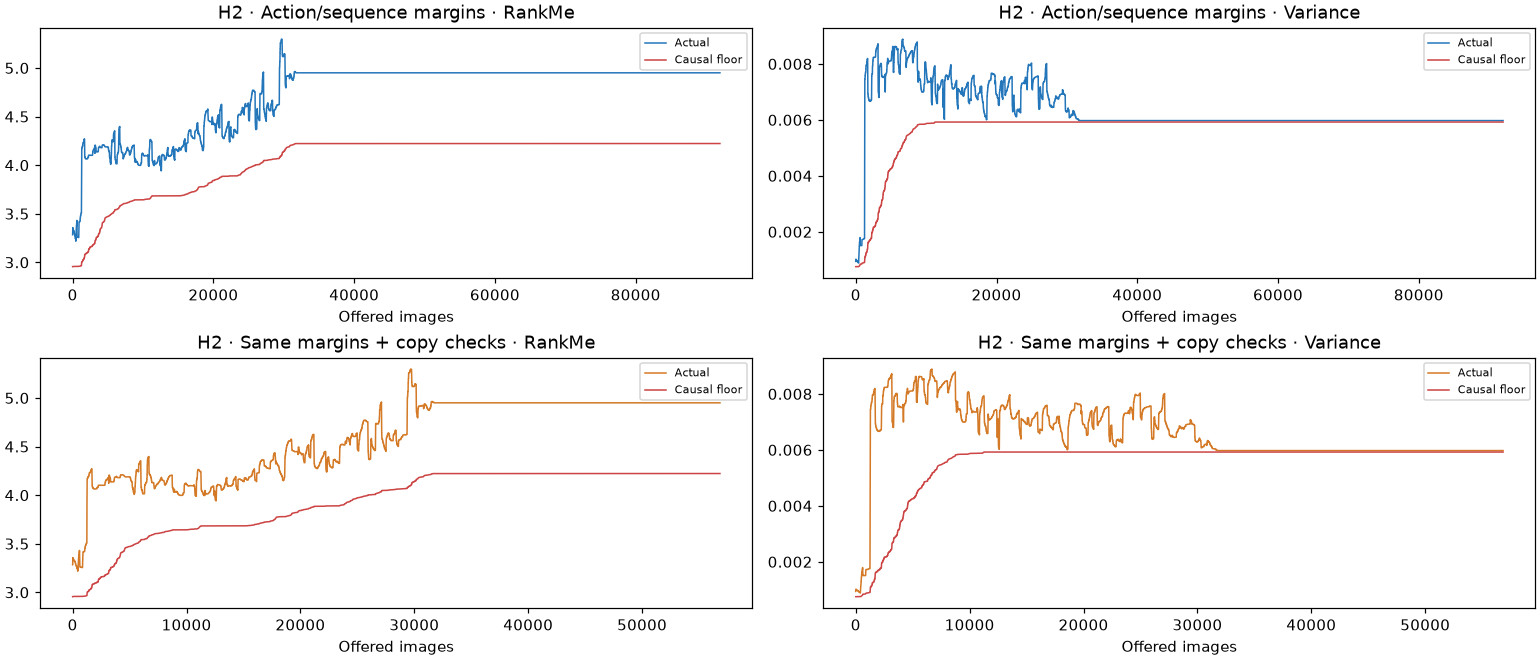



## Prequential chosen-action bound coverage

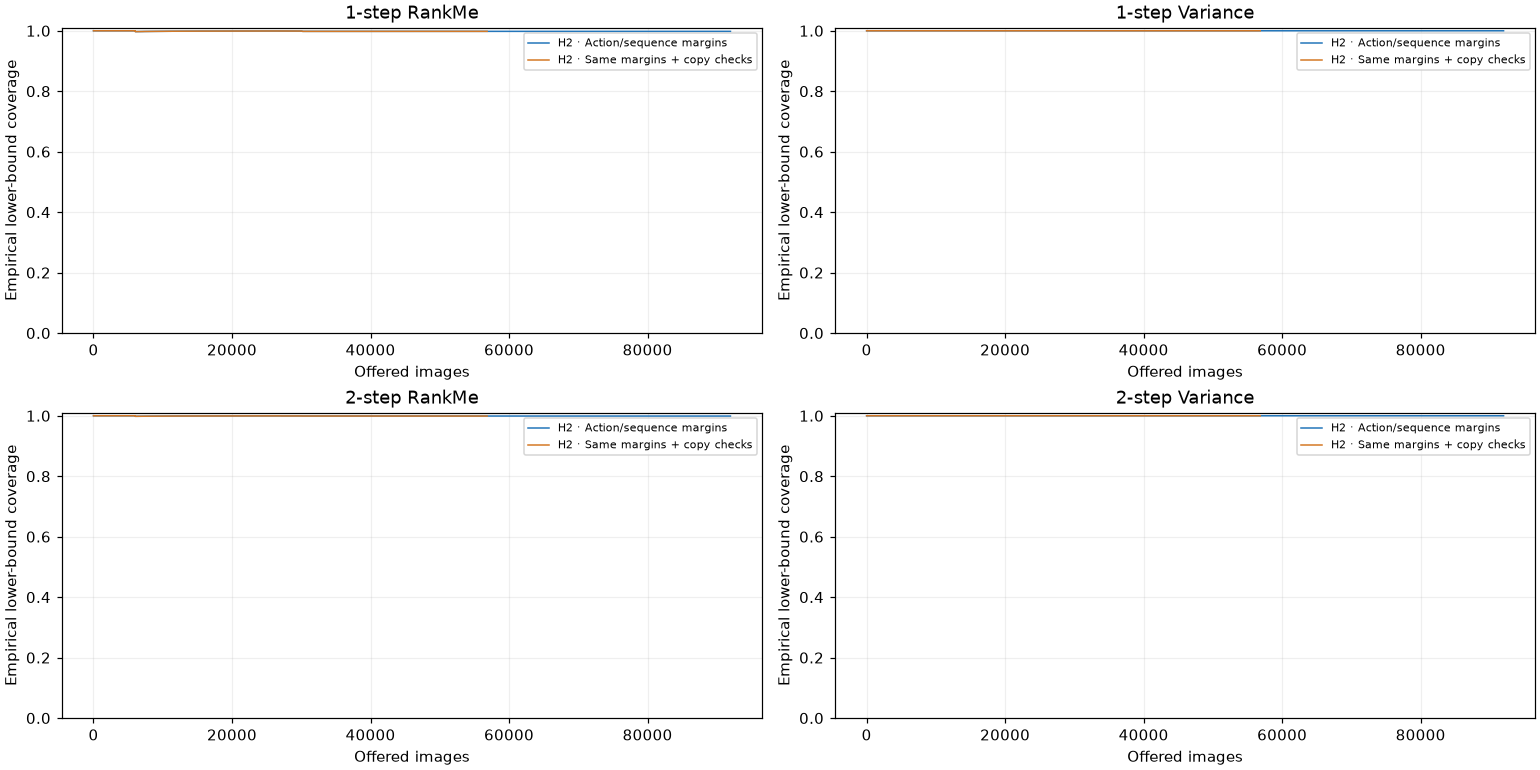

One-step positive updates; two-step nontrivial actual pairs. No claim of policy-independent joint online coverage.

## Filtering, recovery and actual violations

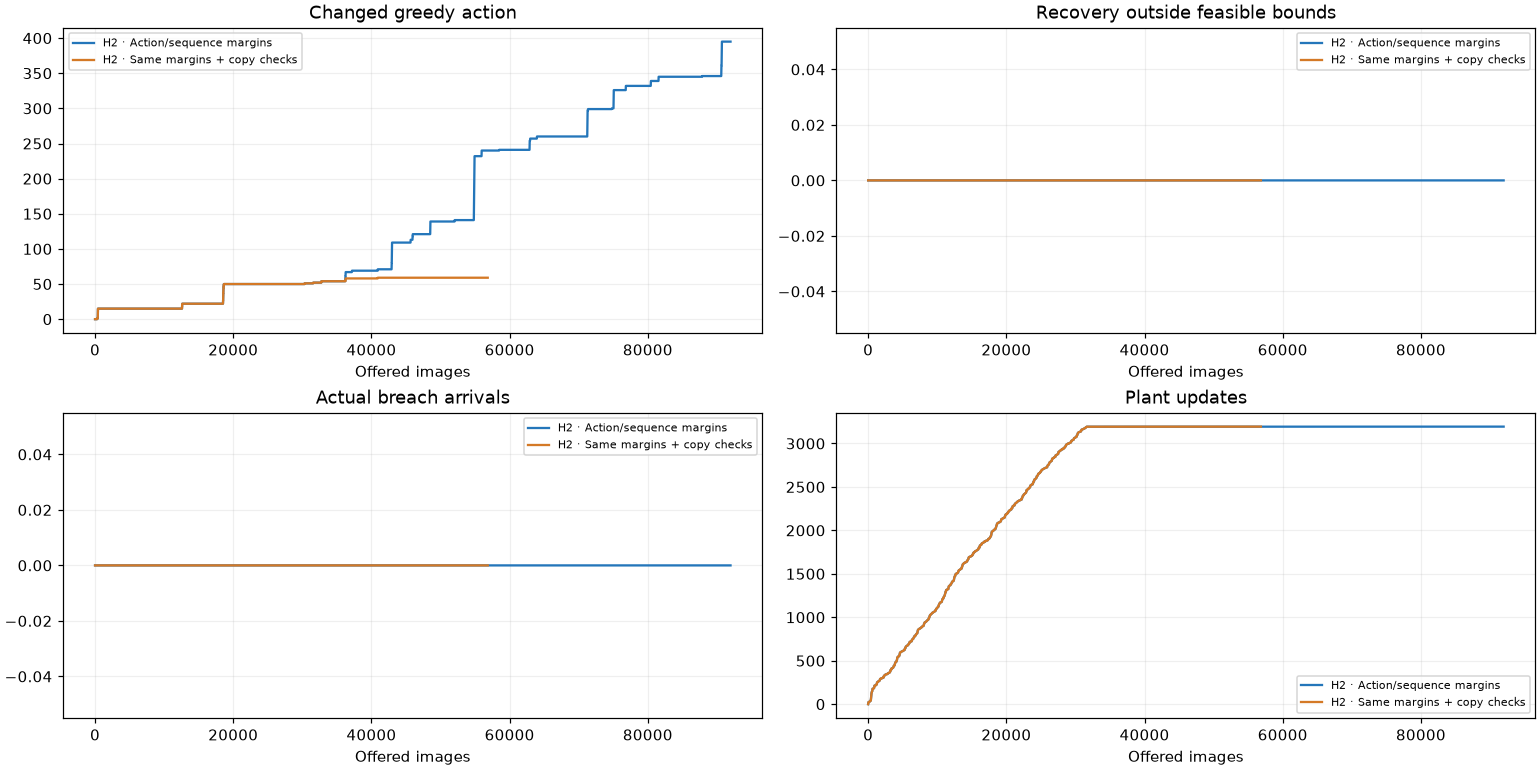



## Direct performance-head prediction error

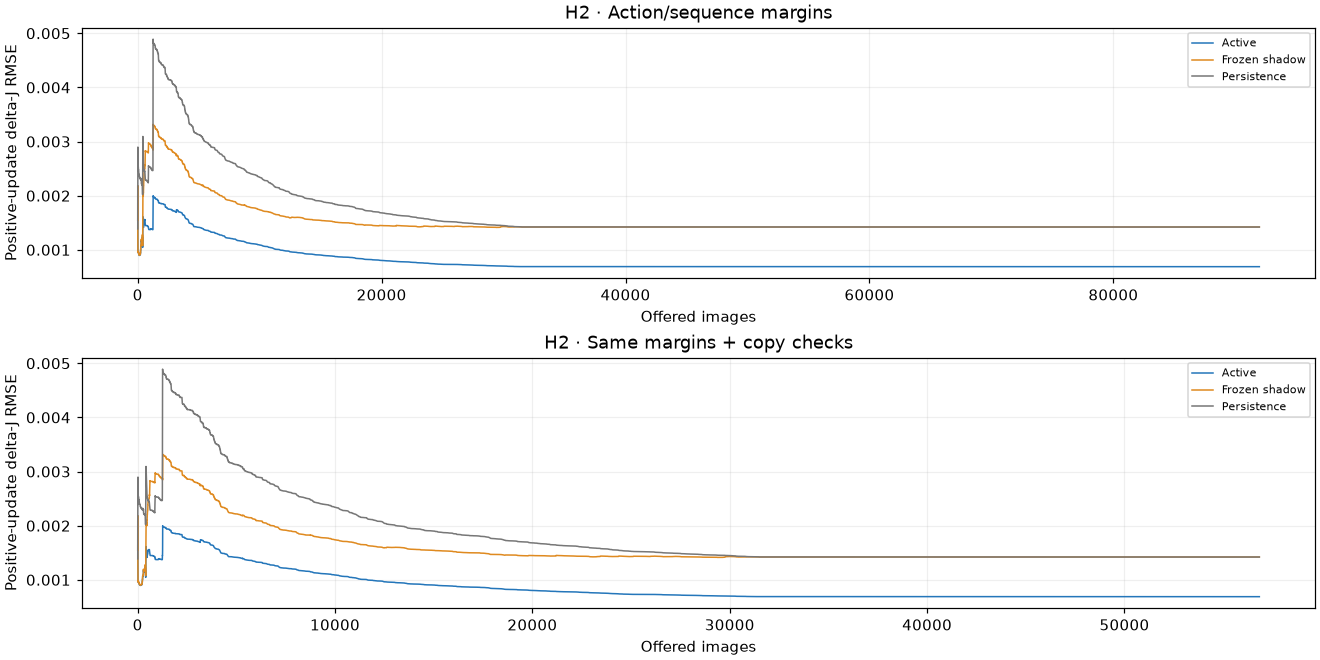



## Audit cost, measured feedback and verified re-entry

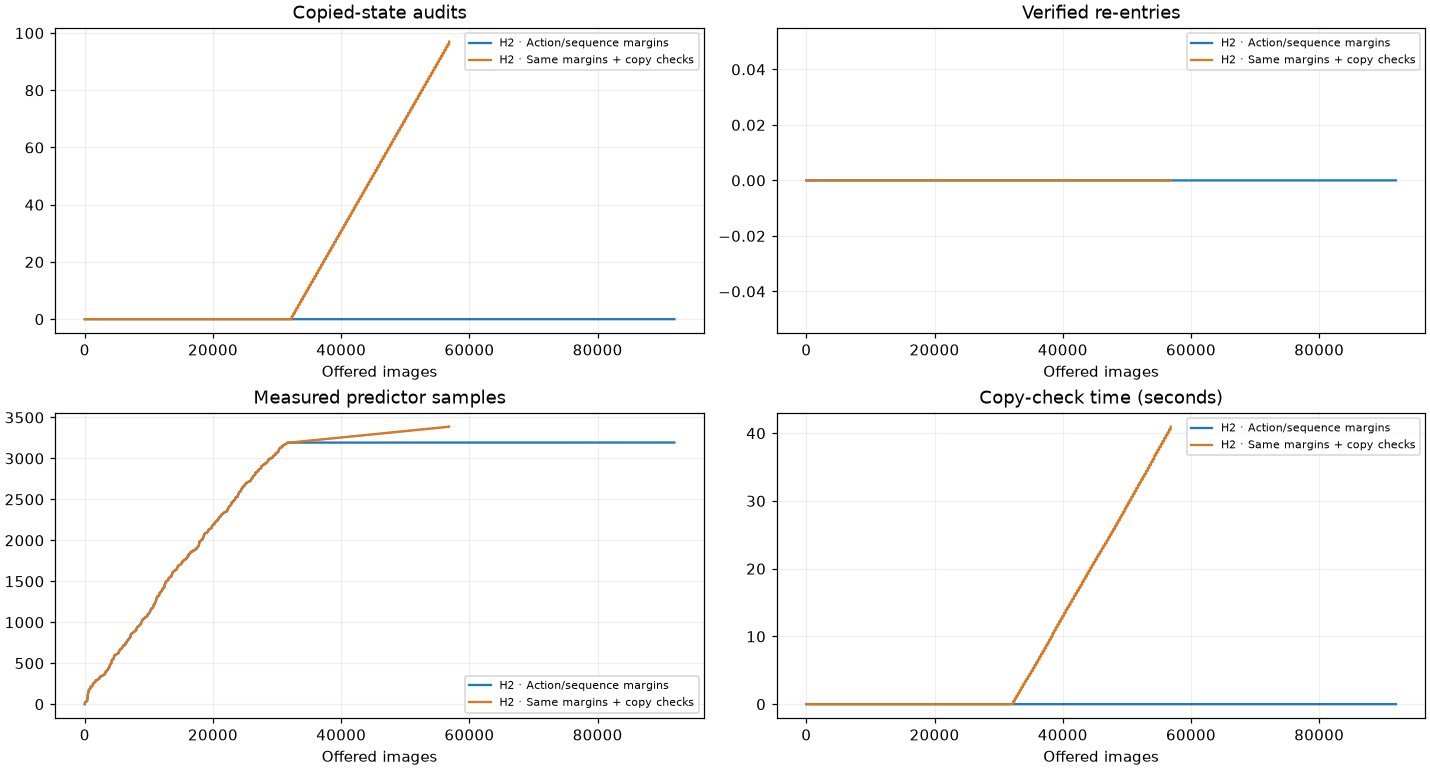

Trials use temporary memory only. Predictor samples include real measurements from uncommitted copies; plant budgets count only committed updates.